# E1 · Limpieza, integración y puerta de calidad
**Observatorio Contabilidad y Cumplimiento Fiscal** · Cristopher Amaro Granero y Yerik Monroy García

Este cuaderno documenta cada decisión de la capa Plata y Oro. El código reutilizable vive en `src/`
(`calidad.py`, `limpieza.py`, `plata.py`, `oro.py`, `pipeline.py`) y el workflow de GitHub Actions lo ejecuta solo;
aquí se muestran los resultados y la justificación.

Fuentes (Bronce, sin modificar): tipo de cambio FIX, TIIE a 28 días y UDIS (diarias) e INPC (mensual), todas de Banxico SIE.

In [1]:
import sys, json, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import calidad, limpieza, plata, oro
RAIZ = pathlib.Path.cwd().parents[1]
pd.set_option("display.width", 160, "display.max_columns", 30)
bronce = plata.leer_bronce(RAIZ)
bronce.groupby("serie").agg(registros=("valor", "size"), desde=("fecha", "min"), hasta=("fecha", "max"))

,registros,desde,hasta
serie,,,
inpc_general_mensual,202,2010-01-01,2026-10-01
tiie_28_dias_diaria,4243,2010-01-04,2026-11-13
tipo_cambio_fix_usd_mxn_diario,4243,2010-01-04,2026-11-13
valor_udis_diario,6164,2010-01-01,2026-11-16


## 1. Puerta de calidad (Pandera) y cuarentena
Antes de pasar a Plata, cada registro de Bronce se valida contra un esquema **estricto**: columnas y tipos exactos,
fuente y serie reconocidas, fecha entre 2010 y hoy, valor positivo, rango plausible por serie y unicidad de `(serie, fecha)`.
Lo que falla **no se borra**: se guarda en `datos/cuarentena/cuarentena.csv` con el motivo.

In [2]:
validos, cuarentena = calidad.compuerta(bronce)
print(f"Bronce: {len(bronce)} | válidos: {len(validos)} | cuarentena: {len(cuarentena)}")

Bronce: 14852 | válidos: 14852 | cuarentena: 0


Con los datos reales de Banxico no hubo rechazos. Para demostrar que la puerta funciona, se prueba con un lote
**de prueba, inventado a propósito**, con seis defectos típicos (no entra al repositorio de datos):

In [3]:
base = dict(fuente="banxico_sie", serie="tipo_cambio_fix_usd_mxn_diario", captura="prueba")
f = lambda fe, v, ft, dt: {**base, "fecha": pd.Timestamp(fe) if fe else pd.NaT, "valor": v, "fecha_texto": ft, "dato_texto": dt}
lote = pd.DataFrame([
    f("2020-01-02", 18.9, "02/01/2020", "18.9"), f("2020-01-02", 19.0, "02/01/2020", "19.0"),
    f(None, 18.9, "31/02/2020", "18.9"),        f("2020-01-03", np.nan, "03/01/2020", "N/E"),
    f("2020-01-06", -1.0, "06/01/2020", "-1"),  f("2020-01-07", 500.0, "07/01/2020", "500"),
    f("2999-01-01", 19.0, "01/01/2999", "19.0"), f("2020-01-08", 19.1, "08/01/2020", "19.1")])
v, q = calidad.compuerta(lote)
print(f"entran {len(lote)} -> válidos {len(v)} + cuarentena {len(q)} (nada se pierde en silencio)")
pd.set_option("display.max_colwidth", 110)
q[["fecha_texto", "dato_texto", "motivo"]]

entran 8 -> válidos 2 + cuarentena 6 (nada se pierde en silencio)


,fecha_texto,dato_texto,motivo
0,02/01/2020,19.0,"multiple_fields_uniqueness [mismo (serie, fecha) ya existe en el lote]"
1,31/02/2020,18.9,not_nullable [NaT]
2,03/01/2020,N/E,not_nullable [nan]
3,06/01/2020,-1,valor_fuera_de_rango_por_serie [valor=-1]; valor_no_positivo [-1.0]
4,07/01/2020,500,valor_fuera_de_rango_por_serie [valor=500]
5,01/01/2999,19.0,fecha_futura [2999-01-01 00:00:00]


## 2. Valores faltantes: diagnóstico del mecanismo e imputación
Las series diarias se llevan a su calendario esperado: días hábiles para FIX y TIIE, todos los días para UDIS, meses para el INPC.
Un hueco es un día del calendario sin dato publicado.

In [4]:
rep = json.loads((RAIZ / "datos/plata/reporte.json").read_text(encoding="utf-8"))
filas = []
for s, i in rep["series"].items():
    d = i["faltantes"]
    filas.append({"serie": s, "faltantes": d["faltantes"], "%": d["pct"], "p_mes": d.get("p_mes"),
                  "p_nivel_previo": d.get("p_nivel_previo"), "p_volatilidad_previa": d.get("p_volatilidad_previa"),
                  "mecanismo": d["mecanismo"]})
pd.DataFrame(filas)

,serie,faltantes,%,p_mes,p_nivel_previo,p_volatilidad_previa,mecanismo
0,inpc_general_mensual,0,0.000,NaN,NaN,NaN,sin huecos suficientes para probar (practicamente completa)
1,tiie_28_dias_diaria,157,3.568,4.636583e-18,0.765863,0.076965,MAR (depende de: mes)
2,tipo_cambio_fix_usd_mxn_diario,157,3.568,4.636583e-18,0.781860,0.096797,MAR (depende de: mes)
3,valor_udis_diario,0,0.000,NaN,NaN,NaN,sin huecos suficientes para probar (practicamente completa)


**Lectura.** FIX y TIIE tienen los mismos días sin dato (feriados bancarios, cuando no se publica). Se probó si la ausencia depende
del mes (χ²), del nivel previo y de la volatilidad previa (Mann-Whitney). El resultado es **MAR**: la ausencia se explica por el
calendario (variable observada), no por el valor mismo que falta. **MNAR** no se puede probar con los datos, pero se descarta por
razón de origen: un feriado no depende del tipo de cambio de ese día. UDIS e INPC no tienen huecos.

**Imputación.** Se ocultó al azar el 5 % de los valores conocidos, se imputaron con tres métodos y se midió el error:

In [5]:
for s, i in rep["series"].items():
    if i["faltantes"]["faltantes"]:
        print(s, "-> método elegido:", i["metodo_imputacion"])
        display(pd.DataFrame(i["imputacion_evaluada"]))

tiie_28_dias_diaria -> método elegido: interpolacion_lineal


,metodo,MAE,RMSE
0,interpolacion_lineal,0.00858,0.02411
1,ultimo_valor (ffill),0.01540,0.05861
2,media_global,2.09999,2.49123


tipo_cambio_fix_usd_mxn_diario -> método elegido: interpolacion_lineal


,metodo,MAE,RMSE
0,interpolacion_lineal,0.06515,0.09175
1,ultimo_valor (ffill),0.08759,0.12954
2,media_global,2.63161,3.08247


Se elige el método de menor error: **interpolación lineal en el tiempo**. Es coherente con la naturaleza de la serie, que cambia de forma
continua entre dos publicaciones. Cada valor imputado queda marcado en la columna `imputado` y el valor original se conserva en `valor`.

## 3. Atípicos y ruido
Se aplican tres detectores a las variaciones logarítmicas diarias: **IQR** (1.5), **Z-Score robusto** (mediana y MAD, |z| > 3.5) e
**Isolation Forest** (1 %). Un punto es atípico de consenso si lo marcan al menos 2.

In [6]:
pd.DataFrame({s: i["atipicos"] for s, i in rep["series"].items()}).T

,atipico_iqr,atipico_zrobusto,atipico_iforest,consenso_2_o_mas
inpc_general_mensual,6,3,2,3
tiie_28_dias_diaria,604,417,44,417
tipo_cambio_fix_usd_mxn_diario,190,85,44,85
valor_udis_diario,246,92,62,92


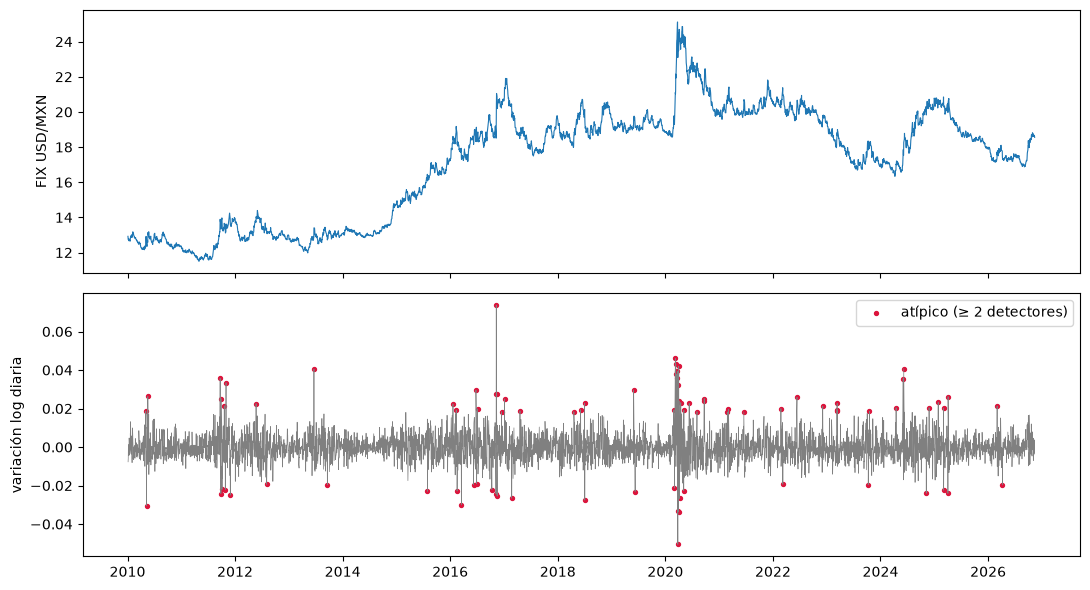

,valor_limpio,variacion_log,n_detectores
fecha,,,
2016-11-09,19.9250,0.073724,3.0
2020-03-26,23.0970,-0.050560,3.0
2020-03-09,21.1117,0.046013,3.0
2020-03-12,22.1518,0.043305,3.0
2020-04-01,24.4918,0.041989,3.0
2024-06-07,18.2622,0.040720,3.0
2013-06-20,13.4015,0.040506,3.0
2020-03-23,25.0782,0.039318,3.0


In [7]:
fix = pd.read_csv(RAIZ / "datos/plata/tipo_cambio_fix_usd_mxn_diario.csv", index_col="fecha", parse_dates=True)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(fix.index, fix["valor_limpio"], lw=.8); ax[0].set_ylabel("FIX USD/MXN")
ax[1].plot(fix.index, fix["variacion_log"], lw=.5, color="gray")
m = fix["n_detectores"] >= 2
ax[1].scatter(fix.index[m], fix["variacion_log"][m], s=8, color="crimson", label="atípico (≥ 2 detectores)")
ax[1].set_ylabel("variación log diaria"); ax[1].legend(); plt.tight_layout(); plt.show()
fix.loc[m, ["valor_limpio", "variacion_log", "n_detectores"]].reindex(fix.loc[m, "variacion_log"].abs().sort_values(ascending=False).index).head(8)

**Tratamiento.** Los atípicos más grandes (9 de noviembre de 2016, tras las elecciones de EE. UU.; marzo de 2020, inicio de la pandemia; 7 de junio de 2024, tras las elecciones en México) coinciden con fechas de eventos y son **movimientos reales
del mercado**, no errores de captura. Por eso **no se eliminan**: se marcan, y para modelado se ofrece la columna `variacion_winsor`
(recorte a los límites IQR). Los errores de captura (valores imposibles) ya los detiene la puerta de calidad.

## 4. Integración de fuentes heterogéneas
| Discrepancia | Fuente | Resolución |
|---|---|---|
| Fecha como texto `dd/mm/aaaa` (Banxico) vs `aaaa/mm` (INEGI) | formato | `plata.leer_bronce` parsea cada formato a `datetime` |
| Valor como texto (`"18.6188"`, `"N/E"`) | tipo | conversión numérica; lo no numérico va a cuarentena |
| Frecuencia diaria (FIX, TIIE, UDIS) vs mensual (INPC) | granularidad | se agrega a una rejilla mensual (`oro.integrar`) |
| Días hábiles vs todos los días | calendario | reindexado a cada calendario antes de imputar |
| Dos fuentes para el INPC (Banxico e INEGI) | redundancia | columna `dif_inpc_banxico_inegi` cuando haya token de INEGI |

In [8]:
integrado = oro.integrar(RAIZ)
print(integrado.shape)
integrado.tail(4).round(3)

(203, 13)


,fix_prom,fix_cierre,fix_std,fix_dias_imputados,tiie_prom,tiie_cierre,udis_prom,udis_cierre,inpc,fix_var_mensual,inflacion_anual,tasa_real,mes_completo
mes,,,,,,,,,,,,,
2026-08,17.066,17.015,0.118,0,6.756,6.766,8.802,8.810,145.462,-2.259,3.262,3.494,True
2026-09,17.260,18.069,0.380,1,6.770,6.816,8.820,8.834,146.075,1.133,3.455,3.316,True
2026-10,18.434,18.796,0.249,0,6.772,6.786,8.856,8.875,147.026,6.803,3.753,3.020,True
2026-11,18.656,18.552,0.071,1,6.662,6.515,8.894,8.912,NaN,1.203,NaN,NaN,False


## 5. Reducción de datos
1. **Agregación:** de 4,243 + 4,243 + 6,164 + 202 observaciones diarias y mensuales a una tabla de **203 meses** (media, cierre y desviación mensual).
2. **Selección de variables** por redundancia: se descarta toda variable con |r| > 0.95 frente a una ya conservada
   (las variables clave `fix_prom`, `tiie_prom`, `inpc` e `inflacion_anual` están protegidas).

In [9]:
orep = json.loads((RAIZ / "datos/oro/reporte.json").read_text(encoding="utf-8"))
print("conservadas:", orep["variables_conservadas"])
pd.Series(orep["variables_descartadas"], name="motivo del descarte").to_frame()

conservadas: ['fix_prom', 'tiie_prom', 'inpc', 'inflacion_anual', 'fix_std', 'fix_var_mensual', 'tasa_real']


,motivo del descarte
fix_cierre,|r|=0.995 con fix_prom
tiie_cierre,|r|=0.999 con tiie_prom
udis_prom,|r|=1.000 con inpc
udis_cierre,|r|=1.000 con inpc


UDIS se descarta por completo porque su valor se calcula a partir del INPC (|r| ≈ 1): no aporta información nueva. Los cierres de mes
son casi idénticos a los promedios (|r| > 0.99). No hizo falta muestreo: el volumen es pequeño y el muestreo habría borrado historia.

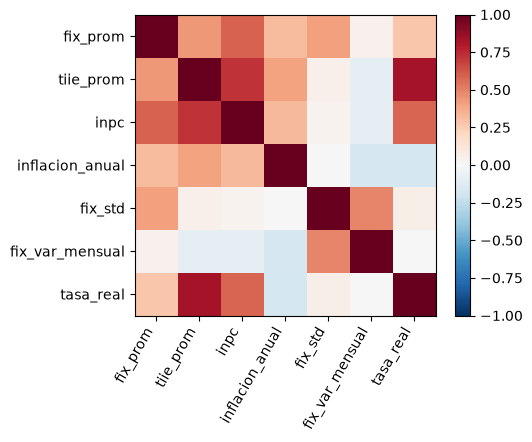

In [10]:
cols = ["fix_prom", "tiie_prom", "inpc", "inflacion_anual", "fix_std", "fix_var_mensual", "tasa_real"]
comp = integrado[integrado["mes_completo"]][cols]
fig, ax = plt.subplots(figsize=(5.5, 4.5)); im = ax.imshow(comp.corr(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right"); ax.set_yticks(range(len(cols)), cols); plt.colorbar(im); plt.tight_layout(); plt.show()

## 6. Normalización
Se generan dos versiones de cada variable continua conservada: **Min-Max** (a [0, 1]) y **Z-Score** (media 0, desviación 1).
Los parámetros quedan guardados en `datos/oro/reporte.json` para poder revertirlas. Nota para E2 y E3: si se modela, los parámetros
deben calcularse solo con el conjunto de entrenamiento.

In [11]:
oro_df = pd.read_csv(RAIZ / "datos/oro/oro_mensual.csv", index_col="mes")
print(oro_df.filter(regex="_mm$").agg(["min", "max"]).round(3).to_string())
print(oro_df.filter(regex="_z$").agg(["mean", "std"]).round(3).to_string())

     fix_prom_mm  tiie_prom_mm  inpc_mm  inflacion_anual_mm  fix_std_mm  fix_var_mensual_mm  tasa_real_mm
min          0.0           0.0      0.0                 0.0         0.0                 0.0           0.0
max          1.0           1.0      1.0                 1.0         1.0                 1.0           1.0
      fix_prom_z  tiie_prom_z  inpc_z  inflacion_anual_z  fix_std_z  fix_var_mensual_z  tasa_real_z
mean      -0.000        0.000   0.000             -0.000     -0.000              0.000       -0.000
std        1.003        1.003   1.003              1.003      1.003              1.003        1.003


## 7. Discretización y jerarquías conceptuales
- **Jerarquía temporal:** mes → trimestre → semestre → año (columnas `trimestre`, `semestre`, `anio`).
- **FIX por terciles** (`bajo`, `medio`, `alto`): intervalos de igual frecuencia.
- **TIIE** por umbrales de política monetaria: `baja` (< 5 %), `media` (5-8 %), `alta` (> 8 %).
- **Inflación anual** según la meta de Banxico (3 % ± 1): `<2%`, `2-4% (meta Banxico)`, `4-6%`, `>6%`.

In [12]:
print("cortes de terciles del FIX:", [round(x, 2) for x in orep["cortes_fix_terciles"]])
oro_df[["trimestre", "fix_prom", "fix_nivel", "tiie_nivel", "inflacion_anual", "inflacion_nivel"]].iloc[[0, 60, 120, -1]].round(2)

cortes de terciles del FIX: [16.98, 19.15]


,trimestre,fix_prom,fix_nivel,tiie_nivel,inflacion_anual,inflacion_nivel
mes,,,,,,
2011-01,2011-T1,12.13,bajo,baja,3.78,2-4% (meta Banxico)
2016-01,2016-T1,18.03,medio,baja,2.61,2-4% (meta Banxico)
2021-01,2021-T1,19.92,alto,baja,3.54,2-4% (meta Banxico)
2026-10,2026-T4,18.43,medio,media,3.75,2-4% (meta Banxico)


In [13]:
pd.crosstab(oro_df["inflacion_nivel"], oro_df["fix_nivel"])

fix_nivel,alto,bajo,medio
inflacion_nivel,,,
2-4% (meta Banxico),22,40,27
4-6%,23,24,25
>6%,18,0,11


## 8. Resultado

In [14]:
print(f"Bronce -> Plata: {rep['validos']} válidos, {rep['cuarentena']} en cuarentena ({rep['pct_cuarentena']} %)")
print(f"Oro: {orep['meses_completos']} meses completos (de {orep['meses_integrados']}); parciales: {len(orep['meses_parciales'])}")
print("Primeros meses parciales:", orep["meses_parciales"][:3], "... último:", orep["meses_parciales"][-1])

Bronce -> Plata: 14852 válidos, 0 en cuarentena (0.0 %)
Oro: 190 meses completos (de 203); parciales: 13
Primeros meses parciales: ['2010-01', '2010-02', '2010-03'] ... último: 2026-11


Los meses parciales no se borran: quedan en `integrado_mensual.csv` con `mes_completo = False`. Son los primeros 12 meses
(la inflación anual necesita 12 meses de historia) y el mes en curso, que aún no tiene INPC publicado.